In [2]:
import numpy as np
import matplotlib.pyplot as plt


def analyse_polarisation(
    Ix_raw,
    Iy_raw,
    I45_raw,
    Im45_raw,
    Iplus_raw,
    Iminus_raw,
    background,
    show_plot=True
):
    """
    Analyse polarisation from six intensity measurements.

    Input order:
        Ix_raw       : intensity measured with polariser along x
        Iy_raw       : intensity measured with polariser along y
        I45_raw      : intensity measured at +45 degrees
        Im45_raw     : intensity measured at -45 degrees
        Iplus_raw    : QWP = +45 degrees, polariser = x
        Iminus_raw   : QWP = -45 degrees, polariser = x
        background   : background intensity subtracted from every measurement
        show_plot    : True to display the polarisation ellipse

    Convention:
        S1 = Ix - Iy
        S2 = I45 - I-45
        S3 = Iplus - Iminus
    """

    # ============================================================
    # 1. Background subtraction
    # ============================================================

    Ix = Ix_raw - background
    Iy = Iy_raw - background

    I45 = I45_raw - background
    Im45 = Im45_raw - background

    Iplus = Iplus_raw - background
    Iminus = Iminus_raw - background

    intensities = np.array(
        [Ix, Iy, I45, Im45, Iplus, Iminus],
        dtype=float
    )

    if np.any(intensities < 0):
        raise ValueError(
            "At least one intensity is negative after background "
            "subtraction. Check the measurements or background value."
        )

    # ============================================================
    # 2. Total intensities in the three measurement bases
    # ============================================================

    S0_xy = Ix + Iy
    S0_45 = I45 + Im45
    S0_circular = Iplus + Iminus

    if S0_xy <= 0:
        raise ValueError("Ix + Iy must be greater than zero.")

    if S0_45 <= 0:
        raise ValueError("I45 + I-45 must be greater than zero.")

    if S0_circular <= 0:
        raise ValueError("Iplus + Iminus must be greater than zero.")

    # Mean total intensity
    S0 = np.mean([S0_xy, S0_45, S0_circular])

    # ============================================================
    # 3. Unnormalised Stokes parameters
    # ============================================================

    S1 = Ix - Iy
    S2 = I45 - Im45
    S3 = Iplus - Iminus

    stokes = np.array([S0, S1, S2, S3])

    # ============================================================
    # 4. Normalised Stokes parameters
    # ============================================================

    s1 = S1 / S0_xy
    s2 = S2 / S0_45
    s3 = S3 / S0_circular

    stokes_normalised = np.array([s1, s2, s3])

    # ============================================================
    # 5. Degrees of polarisation
    # ============================================================

    DOLP = np.sqrt(s1**2 + s2**2)
    DOCP = s3
    DOP = np.sqrt(s1**2 + s2**2 + s3**2)

    # ============================================================
    # 6. Polarisation ellipse orientation
    # ============================================================

    psi = 0.5 * np.arctan2(s2, s1)

    # A Jones vector describes a fully polarised state.
    # Therefore, use the direction of the measured Stokes vector
    # and project it onto the unit Poincare sphere.
    if DOP > 0:
        s1_plot = s1 / DOP
        s2_plot = s2 / DOP
        s3_plot = s3 / DOP
    else:
        s1_plot = 0.0
        s2_plot = 0.0
        s3_plot = 0.0

    chi = 0.5 * np.arcsin(
        np.clip(s3_plot, -1.0, 1.0)
    )

    ellipticity = np.tan(chi)
    axis_ratio = abs(np.tan(chi))

    # ============================================================
    # 7. Jones vector in the x/y basis
    # ============================================================
    #
    # Convention:
    #
    # S1 = |Ex|^2 - |Ey|^2
    # S2 = 2 Re(Ex* Ey)
    # S3 = 2 Im(Ex* Ey)
    #
    # Ex is chosen to be real and non-negative.
    # ============================================================

    if 1 + s1_plot > 1e-12:
        Ex = np.sqrt((1 + s1_plot) / 2)

        Ey = (
            s2_plot + 1j * s3_plot
        ) / np.sqrt(2 * (1 + s1_plot))

    else:
        # Pure or nearly pure y polarisation
        Ex = 0.0 + 0.0j
        Ey = 1.0 + 0.0j

    jones_vector = np.array([Ex, Ey], dtype=complex)

    norm = np.linalg.norm(jones_vector)

    if norm > 0:
        jones_vector = jones_vector / norm

    Ex = jones_vector[0]
    Ey = jones_vector[1]

    # Relative amplitude and phase
    if abs(Ex) > 1e-12:
        relative_amplitude = abs(Ey) / abs(Ex)
        relative_phase = np.angle(Ey / Ex)
    else:
        relative_amplitude = np.inf
        relative_phase = np.nan

    # ============================================================
    # 8. Print results
    # ============================================================

    print("\n========== Background-corrected intensities ==========")
    print(f"Ix     = {Ix:.4f}")
    print(f"Iy     = {Iy:.4f}")
    print(f"I45    = {I45:.4f}")
    print(f"I-45   = {Im45:.4f}")
    print(f"Iplus  = {Iplus:.4f}")
    print(f"Iminus = {Iminus:.4f}")

    print("\n========== Total intensities ==========")
    print(f"Ix + Iy          = {S0_xy:.4f}")
    print(f"I45 + I-45       = {S0_45:.4f}")
    print(f"Iplus + Iminus   = {S0_circular:.4f}")
    print(f"Mean S0          = {S0:.4f}")

    print("\n========== Stokes parameters ==========")
    print(f"S0 = {S0:.4f}")
    print(f"S1 = {S1:.4f}")
    print(f"S2 = {S2:.4f}")
    print(f"S3 = {S3:.4f}")

    print("\n========== Normalised Stokes parameters ==========")
    print(f"s1 = {s1:.4f}")
    print(f"s2 = {s2:.4f}")
    print(f"s3 = {s3:.4f}")

    print("\n========== Degrees of polarisation ==========")
    print(f"DOLP = {DOLP:.4f}")
    print(f"DOCP = {DOCP:.4f}")
    print(f"DOP  = {DOP:.4f}")

    if DOP > 1:
        print(
            "\nWarning: DOP > 1, which is not physically possible."
        )
        print(
            "This normally indicates measurement uncertainty, "
            "power drift, angle error or imperfect calibration."
        )
        print(
            "The Jones vector and ellipse use the Stokes vector "
            "projected onto the unit Poincare sphere."
        )

    print("\n========== Polarisation ellipse ==========")
    print(
        f"Major-axis angle psi = "
        f"{np.degrees(psi):.2f} degrees"
    )
    print(
        f"Ellipticity angle chi = "
        f"{np.degrees(chi):.2f} degrees"
    )
    print(
        f"Ellipticity (signed minor/major axis ratio) = "
        f"{ellipticity:.4f}"
    )
    print(
        f"Minor/major axis ratio = {axis_ratio:.4f}"
    )

    print("\n========== Jones vector in the x/y basis ==========")
    print(jones_vector)

    print("\nEquivalent form with Ex real:")

    if np.isfinite(relative_amplitude):
        print(
            f"|Ey| / |Ex| = {relative_amplitude:.4f}"
        )
        print(
            f"Relative phase delta = "
            f"{np.degrees(relative_phase):.2f} degrees"
        )
    else:
        print("|Ey| / |Ex| = infinity")
        print(
            "Relative phase is undefined because Ex is zero."
        )

    # ============================================================
    # 9. Plot polarisation ellipse
    # ============================================================

    if show_plot:
        t = np.linspace(0, 2 * np.pi, 1000)

        electric_field = (
            jones_vector[:, None]
            * np.exp(1j * t)[None, :]
        ).real

        Ex_t = electric_field[0]
        Ey_t = electric_field[1]

        fig, ax = plt.subplots(figsize=(7, 7))

        ax.plot(
            Ex_t,
            Ey_t,
            linewidth=2,
            label="Polarisation ellipse"
        )

        # Laboratory axes
        ax.axhline(0, linewidth=0.8)
        ax.axvline(0, linewidth=0.8)

        # Arrow showing the direction of increasing time
        arrow_index = 130
        step = 15

        ax.annotate(
            "",
            xy=(
                Ex_t[arrow_index + step],
                Ey_t[arrow_index + step]
            ),
            xytext=(
                Ex_t[arrow_index],
                Ey_t[arrow_index]
            ),
            arrowprops=dict(
                arrowstyle="->",
                linewidth=2
            )
        )

        # Major axis
        axis_length = 1.0

        axis_x = axis_length * np.cos(psi)
        axis_y = axis_length * np.sin(psi)

        ax.plot(
            [-axis_x, axis_x],
            [-axis_y, axis_y],
            linestyle="--",
            linewidth=1.2,
            label=(
                rf"Major axis: "
                rf"$\psi={np.degrees(psi):.1f}^\circ$"
            )
        )

        ax.set_xlabel("X (horizontal)")
        ax.set_ylabel("Y (vertical)")

        ax.set_title(
            "Polarisation ellipse in lab coordinates\n"
            + rf"$s_1={s1:.3f},\ "
            + rf"s_2={s2:.3f},\ "
            + rf"s_3={s3:.3f}$"
        )

        # Signed minor/major axis ratio
        ax.text(
            0.97,
            0.97,
            rf"Ellipticity $= {ellipticity:.3f}$",
            transform=ax.transAxes,
            ha="right",
            va="top"
        )

        # Fixed equal axes to avoid deformation
        ax.set_xlim(-1, 1)
        ax.set_ylim(-1, 1)
        ax.set_aspect("equal", adjustable="box")

        ax.grid(alpha=0.3)
        ax.legend(frameon=False)

        plt.tight_layout()
        plt.show()

    # ============================================================
    # 10. Return all calculated results
    # ============================================================

    results = {
        "corrected_intensities": {
            "Ix": Ix,
            "Iy": Iy,
            "I45": I45,
            "Im45": Im45,
            "Iplus": Iplus,
            "Iminus": Iminus
        },

        "total_intensities": {
            "S0_xy": S0_xy,
            "S0_45": S0_45,
            "S0_circular": S0_circular
        },

        "stokes": stokes,

        "normalised_stokes": stokes_normalised,

        "DOLP": DOLP,
        "DOCP": DOCP,
        "DOP": DOP,

        "psi_radians": psi,
        "psi_degrees": np.degrees(psi),

        "chi_radians": chi,
        "chi_degrees": np.degrees(chi),

        "ellipticity": ellipticity,
        "axis_ratio": axis_ratio,

        "jones_vector": jones_vector,

        "relative_amplitude": relative_amplitude,
        "relative_phase_radians": relative_phase,
        "relative_phase_degrees": np.degrees(relative_phase)
        if np.isfinite(relative_phase)
        else np.nan
    }

    return results



========== Background-corrected intensities ==========
Ix     = 2.9000
Iy     = 7.2000
I45    = 5.8500
I-45   = 2.9000
Iplus  = 7.8000
Iminus = 0.9000

========== Total intensities ==========
Ix + Iy          = 10.1000
I45 + I-45       = 8.7500
Iplus + Iminus   = 8.7000
Mean S0          = 9.1833

========== Stokes parameters ==========
S0 = 9.1833
S1 = -4.3000
S2 = 2.9500
S3 = 6.9000

========== Normalised Stokes parameters ==========
s1 = -0.4257
s2 = 0.3371
s3 = 0.7931

========== Degrees of polarisation ==========
DOLP = 0.5431
DOCP = 0.7931
DOP  = 0.9612

========== Polarisation ellipse ==========
Major-axis angle psi = 70.81 degrees
Ellipticity angle chi = 27.80 degrees
Minor/major axis ratio = 0.5272

========== Jones vector in the x/y basis ==========
[0.52776838+0.j         0.33229198+0.78169212j]

Equivalent form with Ex real:
|Ey| / |Ex| = 1.6094
Relative phase delta = 66.97 degrees


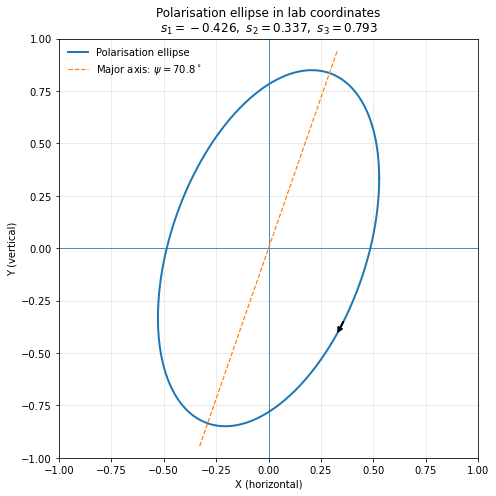

In [11]:

# ================================================================
# Example: enter the measurements in this order:
#
# Ix, Iy, I45, I-45, Iplus, Iminus, background
# ================================================================

results = analyse_polarisation(
    3.5,    # Ix
    7.8,    # Iy
    6.45,   # I45
    3.5,    # I-45
    8.4,    # Iplus:  QWP = +45 degrees, polariser = x
    1.5,    # Iminus: QWP = -45 degrees, polariser = x
    0.6     # background
)


========== Background-corrected intensities ==========
Ix     = 15.8000
Iy     = 4.1000
I45    = 7.6000
I-45   = 14.2000
Iplus  = 2.7000
Iminus = 15.8000

========== Total intensities ==========
Ix + Iy          = 19.9000
I45 + I-45       = 21.8000
Iplus + Iminus   = 18.5000
Mean S0          = 20.0667

========== Stokes parameters ==========
S0 = 20.0667
S1 = 11.7000
S2 = -6.6000
S3 = -13.1000

========== Normalised Stokes parameters ==========
s1 = 0.5879
s2 = -0.3028
s3 = -0.7081

========== Degrees of polarisation ==========
DOLP = 0.6613
DOCP = -0.7081
DOP  = 0.9689

========== Polarisation ellipse ==========
Major-axis angle psi = -13.62 degrees
Ellipticity angle chi = -23.48 degrees
Minor/major axis ratio = 0.4344

========== Jones vector in the x/y basis ==========
[ 0.89633068+0.j         -0.17430683-0.40768669j]

Equivalent form with Ex real:
|Ey| / |Ex| = 0.4947
Relative phase delta = -113.15 degrees


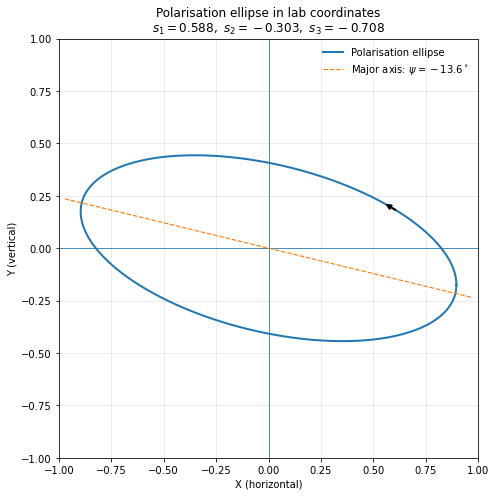

In [6]:
results2 = analyse_polarisation(
    16,    # Ix
    4.3,    # Iy
    7.8,   # I45
    14.4,    # I-45
    2.9,    # Iplus:  QWP = +45 degrees, polariser = x
    16,    # Iminus: QWP = -45 degrees, polariser = x
    0.2     # background
)


========== Background-corrected intensities ==========
Ix     = 3.3500
Iy     = 5.7000
I45    = 2.3400
I-45   = 6.5000
Iplus  = 1.1700
Iminus = 8.3000

========== Total intensities ==========
Ix + Iy          = 9.0500
I45 + I-45       = 8.8400
Iplus + Iminus   = 9.4700
Mean S0          = 9.1200

========== Stokes parameters ==========
S0 = 9.1200
S1 = -2.3500
S2 = -4.1600
S3 = -7.1300

========== Normalised Stokes parameters ==========
s1 = -0.2597
s2 = -0.4706
s3 = -0.7529

========== Degrees of polarisation ==========
DOLP = 0.5375
DOCP = -0.7529
DOP  = 0.9251

========== Polarisation ellipse ==========
Major-axis angle psi = -59.44 degrees
Ellipticity angle chi = -27.24 degrees
Minor/major axis ratio = 0.5148

========== Jones vector in the x/y basis ==========
[ 0.59970702+0.j         -0.42413066-0.67857547j]

Equivalent form with Ex real:
|Ey| / |Ex| = 1.3344
Relative phase delta = -122.01 degrees


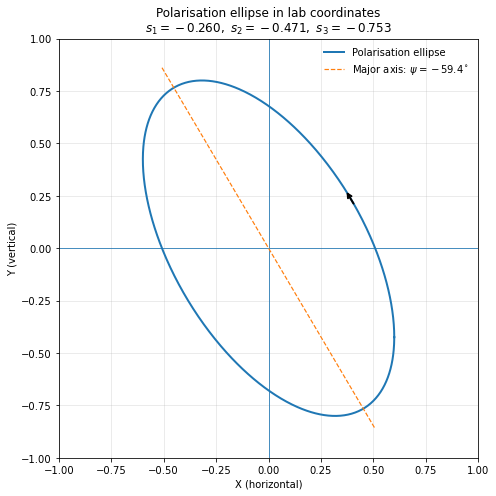

In [3]:
result3 = analyse_polarisation(
    3.65,
    6,
    2.64,
    6.8,
    1.47,
    8.6,
    0.3
)


========== Background-corrected intensities ==========
Ix     = 3.6500
Iy     = 6.7000
I45    = 2.6700
I-45   = 7.0000
Iplus  = 1.0900
Iminus = 9.0000

========== Total intensities ==========
Ix + Iy          = 10.3500
I45 + I-45       = 9.6700
Iplus + Iminus   = 10.0900
Mean S0          = 10.0367

========== Stokes parameters ==========
S0 = 10.0367
S1 = -3.0500
S2 = -4.3300
S3 = -7.9100

========== Normalised Stokes parameters ==========
s1 = -0.2947
s2 = -0.4478
s3 = -0.7839

========== Degrees of polarisation ==========
DOLP = 0.5360
DOCP = -0.7839
DOP  = 0.9497

========== Polarisation ellipse ==========
Major-axis angle psi = -61.67 degrees
Ellipticity angle chi = -27.82 degrees
Minor/major axis ratio = 0.5276

========== Jones vector in the x/y basis ==========
[ 0.58724069+0.j         -0.40145145-0.70284074j]

Equivalent form with Ex real:
|Ey| / |Ex| = 1.3783
Relative phase delta = -119.73 degrees


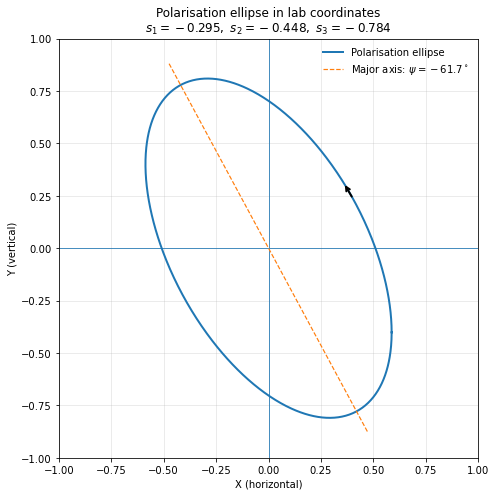

In [4]:
result4 = analyse_polarisation(
    3.95,
    7,
    2.97,
    7.3,
    1.39,
    9.3,
    0.3
)


========== Background-corrected intensities ==========
Ix     = 2.2000
Iy     = 1.5000
I45    = 2.9300
I-45   = 0.8000
Iplus  = 2.7600
Iminus = 0.7300

========== Total intensities ==========
Ix + Iy          = 3.7000
I45 + I-45       = 3.7300
Iplus + Iminus   = 3.4900
Mean S0          = 3.6400

========== Stokes parameters ==========
S0 = 3.6400
S1 = 0.7000
S2 = 2.1300
S3 = 2.0300

========== Normalised Stokes parameters ==========
s1 = 0.1892
s2 = 0.5710
s3 = 0.5817

========== Degrees of polarisation ==========
DOLP = 0.6016
DOCP = 0.5817
DOP  = 0.8368

========== Polarisation ellipse ==========
Major-axis angle psi = 35.83 degrees
Ellipticity angle chi = 22.02 degrees
Minor/major axis ratio = 0.4044

========== Jones vector in the x/y basis ==========
[0.78297172+0.j         0.43579138+0.44389318j]

Equivalent form with Ex real:
|Ey| / |Ex| = 0.7945
Relative phase delta = 45.53 degrees


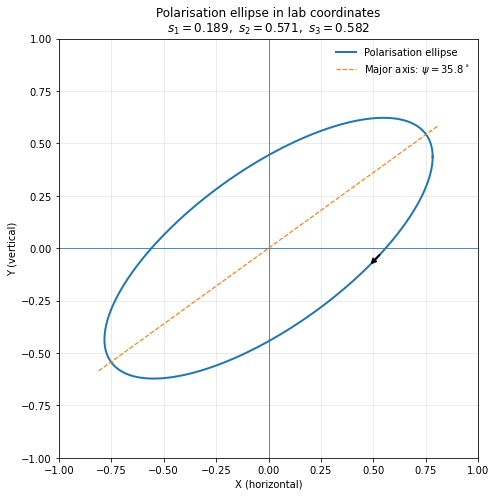

In [7]:
flippedstate = analyse_polarisation(
    2.4,
    1.7,
    3.13,
    1,
    2.96,
    0.93,
    0.2,
)


========== Background-corrected intensities ==========
Ix     = 14.6000
Iy     = 10.3000
I45    = 19.1000
I-45   = 4.3000
Iplus  = 16.4000
Iminus = 3.7000

========== Total intensities ==========
Ix + Iy          = 24.9000
I45 + I-45       = 23.4000
Iplus + Iminus   = 20.1000
Mean S0          = 22.8000

========== Stokes parameters ==========
S0 = 22.8000
S1 = 4.3000
S2 = 14.8000
S3 = 12.7000

========== Normalised Stokes parameters ==========
s1 = 0.1727
s2 = 0.6325
s3 = 0.6318

========== Degrees of polarisation ==========
DOLP = 0.6556
DOCP = 0.6318
DOP  = 0.9105

========== Polarisation ellipse ==========
Major-axis angle psi = 37.36 degrees
Ellipticity angle chi = 21.97 degrees
Minor/major axis ratio = 0.4034

========== Jones vector in the x/y basis ==========
[0.77125176+0.j         0.45032185+0.44986771j]

Equivalent form with Ex real:
|Ey| / |Ex| = 0.8253
Relative phase delta = 44.97 degrees


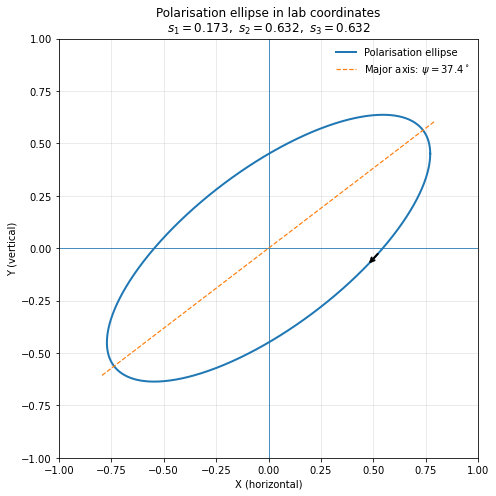

In [8]:
cavitymode2= analyse_polarisation(
    14.8,
    10.5,
    19.3,
    4.5,
    16.6,
    3.9,
    0.2,
)


========== Background-corrected intensities ==========
Ix     = 2.6000
Iy     = 5.2000
I45    = 2.0000
I-45   = 5.0500
Iplus  = 1.1000
Iminus = 5.7000

========== Total intensities ==========
Ix + Iy          = 7.8000
I45 + I-45       = 7.0500
Iplus + Iminus   = 6.8000
Mean S0          = 7.2167

========== Stokes parameters ==========
S0 = 7.2167
S1 = -2.6000
S2 = -3.0500
S3 = -4.6000

========== Normalised Stokes parameters ==========
s1 = -0.3333
s2 = -0.4326
s3 = -0.6765

========== Degrees of polarisation ==========
DOLP = 0.5461
DOCP = -0.6765
DOP  = 0.8694

========== Polarisation ellipse ==========
Major-axis angle psi = -63.81 degrees
Ellipticity angle chi = -25.54 degrees
Minor/major axis ratio = 0.4779

========== Jones vector in the x/y basis ==========
[ 0.55524843+0.j         -0.44808963-0.70065317j]

Equivalent form with Ex real:
|Ey| / |Ex| = 1.4979
Relative phase delta = -122.60 degrees


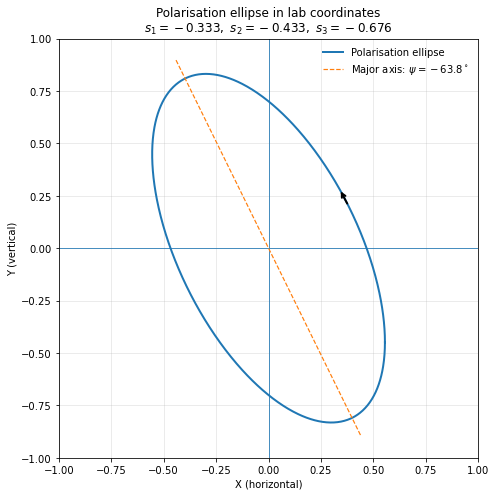

In [9]:
cavitymode3= analyse_polarisation(
    2.9,
    5.5,
    2.3,
    5.35,
    1.4,
    6.0,
    0.3,
)


========== Background-corrected intensities ==========
Ix     = 7.3000
Iy     = 5.2700
I45    = 0.0700
I-45   = 12.2800
Iplus  = 5.4100
Iminus = 6.5700

========== Total intensities ==========
Ix + Iy          = 12.5700
I45 + I-45       = 12.3500
Iplus + Iminus   = 11.9800
Mean S0          = 12.3000

========== Stokes parameters ==========
S0 = 12.3000
S1 = 2.0300
S2 = -12.2100
S3 = -1.1600

========== Normalised Stokes parameters ==========
s1 = 0.1615
s2 = -0.9887
s3 = -0.0968

========== Degrees of polarisation ==========
DOLP = 1.0018
DOCP = -0.0968
DOP  = 1.0064

This normally indicates measurement uncertainty, power drift, angle error or imperfect calibration.
The Jones vector and ellipse use the Stokes vector projected onto the unit Poincare sphere.

========== Polarisation ellipse ==========
Major-axis angle psi = -40.36 degrees
Ellipticity angle chi = -2.76 degrees
Minor/major axis ratio = 0.0482

========== Jones vector in the x/y basis ==========
[ 0.76172926+0.j         -0

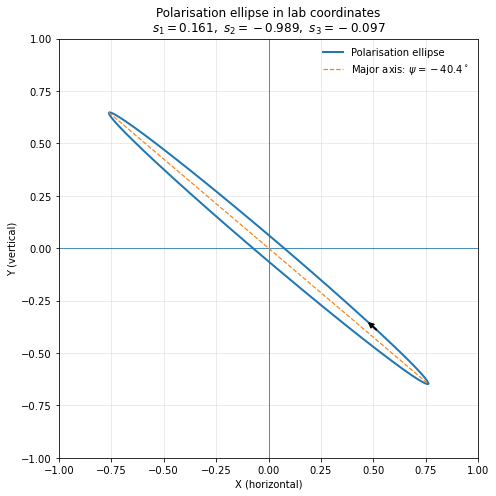

In [10]:
lasertest = analyse_polarisation(
    7.4,
    5.37,
    0.17,
    12.38,
    5.51,
    6.67,
    0.1
)


========== Background-corrected intensities ==========
Ix     = 2.1700
Iy     = 3.4500
I45    = 1.6000
I-45   = 3.8700
Iplus  = 0.8000
Iminus = 3.7000

========== Total intensities ==========
Ix + Iy          = 5.6200
I45 + I-45       = 5.4700
Iplus + Iminus   = 4.5000
Mean S0          = 5.1967

========== Stokes parameters ==========
S0 = 5.1967
S1 = -1.2800
S2 = -2.2700
S3 = -2.9000

========== Normalised Stokes parameters ==========
s1 = -0.2278
s2 = -0.4150
s3 = -0.6444

========== Degrees of polarisation ==========
DOLP = 0.4734
DOCP = -0.6444
DOP  = 0.7996

========== Polarisation ellipse ==========
Major-axis angle psi = -59.38 degrees
Ellipticity angle chi = -26.85 degrees
Minor/major axis ratio = 0.5062

========== Jones vector in the x/y basis ==========
[ 0.59798365+0.j         -0.4339433 -0.67387593j]

Equivalent form with Ex real:
|Ey| / |Ex| = 1.3404
Relative phase delta = -122.78 degrees


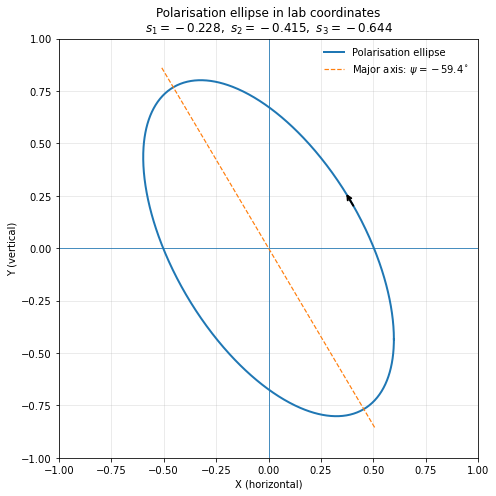

In [13]:
nearthreshold = analyse_polarisation(
    2.37,
    3.65,
    1.8,
    4.07,
    1.0,
    3.9,
    0.2
)

#threshold = 29mW, test at 32mW


========== Background-corrected intensities ==========
Ix     = 13.9300
Iy     = 21.8000
I45    = 9.7000
I-45   = 26.4000
Iplus  = 3.9000
Iminus = 29.1000

========== Total intensities ==========
Ix + Iy          = 35.7300
I45 + I-45       = 36.1000
Iplus + Iminus   = 33.0000
Mean S0          = 34.9433

========== Stokes parameters ==========
S0 = 34.9433
S1 = -7.8700
S2 = -16.7000
S3 = -25.2000

========== Normalised Stokes parameters ==========
s1 = -0.2203
s2 = -0.4626
s3 = -0.7636

========== Degrees of polarisation ==========
DOLP = 0.5124
DOCP = -0.7636
DOP  = 0.9196

========== Polarisation ellipse ==========
Major-axis angle psi = -57.73 degrees
Ellipticity angle chi = -28.07 degrees
Minor/major axis ratio = 0.5333

========== Jones vector in the x/y basis ==========
[ 0.6166355 +0.j         -0.40789952-0.67333397j]

Equivalent form with Ex real:
|Ey| / |Ex| = 1.2767
Relative phase delta = -121.21 degrees


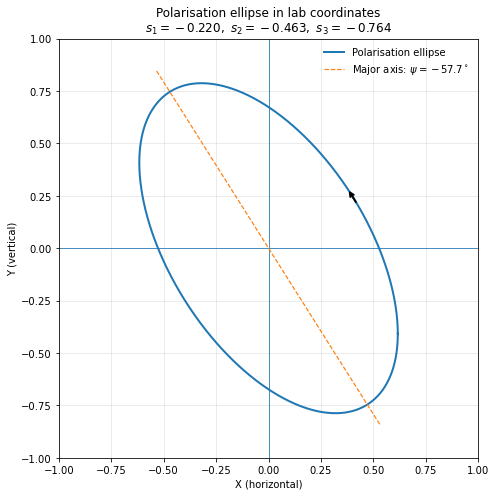

In [14]:
two_x_threshold = analyse_polarisation(
    14.13,
    22,
    9.9,
    26.6,
    4.1,
    29.3,
    0.2
)

#measurement at 60mW


========== Background-corrected intensities ==========
Ix     = 6.8000
Iy     = 1.4000
I45    = 3.6000
I-45   = 5.7000
Iplus  = 1.0000
Iminus = 6.1000

========== Total intensities ==========
Ix + Iy          = 8.2000
I45 + I-45       = 9.3000
Iplus + Iminus   = 7.1000
Mean S0          = 8.2000

========== Stokes parameters ==========
S0 = 8.2000
S1 = 5.4000
S2 = -2.1000
S3 = -5.1000

========== Normalised Stokes parameters ==========
s1 = 0.6585
s2 = -0.2258
s3 = -0.7183

========== Degrees of polarisation ==========
DOLP = 0.6962
DOCP = -0.7183
DOP  = 1.0003

This normally indicates measurement uncertainty, power drift, angle error or imperfect calibration.
The Jones vector and ellipse use the Stokes vector projected onto the unit Poincare sphere.

========== Polarisation ellipse ==========
Major-axis angle psi = -9.46 degrees
Ellipticity angle chi = -22.95 degrees
Ellipticity (signed minor/major axis ratio) = -0.4234
Minor/major axis ratio = 0.4234

========== Jones vector in the x

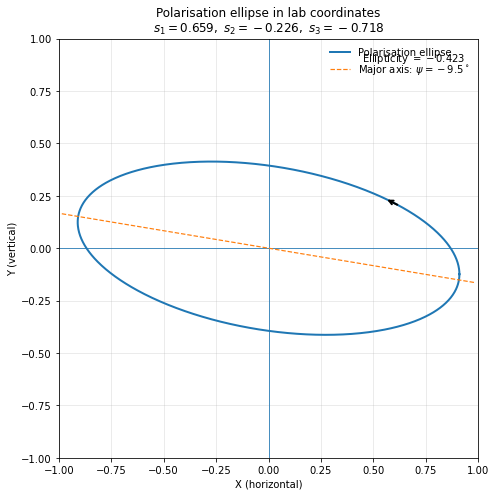

In [11]:
rotated_pump_beam_10 = analyse_polarisation(
    7,
    1.6,
    3.8,
    5.9,
    1.2,
    6.3,
    0.2
)
 #Input order:
        #Ix_raw       : intensity measured with polariser along x
        #Iy_raw       : intensity measured with polariser along y
        #I45_raw      : intensity measured at +45 degrees
        #Im45_raw     : intensity measured at -45 degrees
        #Iplus_raw    : QWP = +45 degrees, polariser = x
        #Iminus_raw   : QWP = -45 degrees, polariser = x
        #background


========== Background-corrected intensities ==========
Ix     = 6.9900
Iy     = 1.5900
I45    = 3.7900
I-45   = 5.9900
Iplus  = 1.1300
Iminus = 6.9900

========== Total intensities ==========
Ix + Iy          = 8.5800
I45 + I-45       = 9.7800
Iplus + Iminus   = 8.1200
Mean S0          = 8.8267

========== Stokes parameters ==========
S0 = 8.8267
S1 = 5.4000
S2 = -2.2000
S3 = -5.8600

========== Normalised Stokes parameters ==========
s1 = 0.6294
s2 = -0.2249
s3 = -0.7217

========== Degrees of polarisation ==========
DOLP = 0.6684
DOCP = -0.7217
DOP  = 0.9836

========== Polarisation ellipse ==========
Major-axis angle psi = -9.83 degrees
Ellipticity angle chi = -23.60 degrees
Ellipticity (signed minor/major axis ratio) = -0.4369
Minor/major axis ratio = 0.4369

========== Jones vector in the x/y basis ==========
[ 0.90549605+0.j         -0.12628053-0.40512977j]

Equivalent form with Ex real:
|Ey| / |Ex| = 0.4686
Relative phase delta = -107.31 degrees


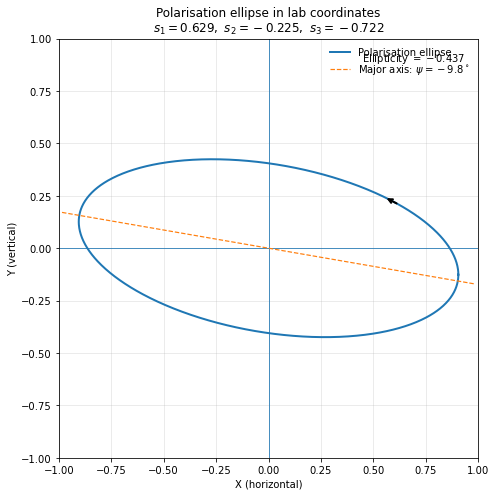

In [9]:
rotated_pump_beam_0 = analyse_polarisation(
    7,
    1.6,
    3.8,
    6,
    1.14,
    7,
    0.01
)
 #Input order:
        #Ix_raw       : intensity measured with polariser along x
        #Iy_raw       : intensity measured with polariser along y
        #I45_raw      : intensity measured at +45 degrees
        #Im45_raw     : intensity measured at -45 degrees
        #Iplus_raw    : QWP = +45 degrees, polariser = x
        #Iminus_raw   : QWP = -45 degrees, polariser = x
        #background


========== Background-corrected intensities ==========
Ix     = 6.1900
Iy     = 1.3400
I45    = 3.9500
I-45   = 5.5500
Iplus  = 0.9700
Iminus = 6.8600

========== Total intensities ==========
Ix + Iy          = 7.5300
I45 + I-45       = 9.5000
Iplus + Iminus   = 7.8300
Mean S0          = 8.2867

========== Stokes parameters ==========
S0 = 8.2867
S1 = 4.8500
S2 = -1.6000
S3 = -5.8900

========== Normalised Stokes parameters ==========
s1 = 0.6441
s2 = -0.1684
s3 = -0.7522

========== Degrees of polarisation ==========
DOLP = 0.6657
DOCP = -0.7522
DOP  = 1.0045

This normally indicates measurement uncertainty, power drift, angle error or imperfect calibration.
The Jones vector and ellipse use the Stokes vector projected onto the unit Poincare sphere.

========== Polarisation ellipse ==========
Major-axis angle psi = -7.33 degrees
Ellipticity angle chi = -24.25 degrees
Ellipticity (signed minor/major axis ratio) = -0.4504
Minor/major axis ratio = 0.4504

========== Jones vector in the x

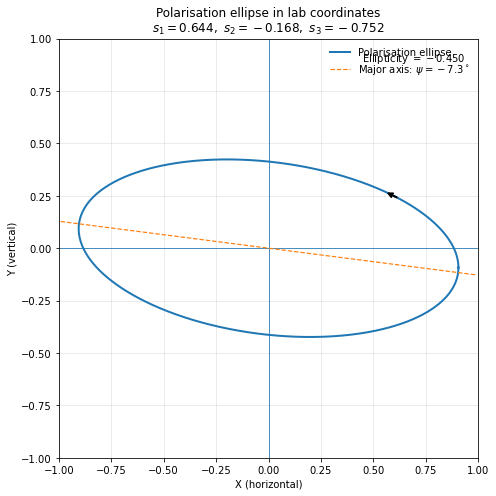

In [10]:
rotated_pump_beam_10 = analyse_polarisation(
    6.2,
    1.35,
    3.96,
    5.56,
    0.98,
    6.87,
    0.01
)
 #Input order:
        #Ix_raw       : intensity measured with polariser along x
        #Iy_raw       : intensity measured with polariser along y
        #I45_raw      : intensity measured at +45 degrees
        #Im45_raw     : intensity measured at -45 degrees
        #Iplus_raw    : QWP = +45 degrees, polariser = x
        #Iminus_raw   : QWP = -45 degrees, polariser = x
        #background


========== Background-corrected intensities ==========
Ix     = 4.9900
Iy     = 1.1700
I45    = 2.3900
I-45   = 3.9900
Iplus  = 0.7800
Iminus = 4.4900

========== Total intensities ==========
Ix + Iy          = 6.1600
I45 + I-45       = 6.3800
Iplus + Iminus   = 5.2700
Mean S0          = 5.9367

========== Stokes parameters ==========
S0 = 5.9367
S1 = 3.8200
S2 = -1.6000
S3 = -3.7100

========== Normalised Stokes parameters ==========
s1 = 0.6201
s2 = -0.2508
s3 = -0.7040

========== Degrees of polarisation ==========
DOLP = 0.6689
DOCP = -0.7040
DOP  = 0.9711

========== Polarisation ellipse ==========
Major-axis angle psi = -11.01 degrees
Ellipticity angle chi = -23.23 degrees
Ellipticity (signed minor/major axis ratio) = -0.4293
Minor/major axis ratio = 0.4293

========== Jones vector in the x/y basis ==========
[ 0.90514656+0.j         -0.14265384-0.40044923j]

Equivalent form with Ex real:
|Ey| / |Ex| = 0.4696
Relative phase delta = -109.61 degrees


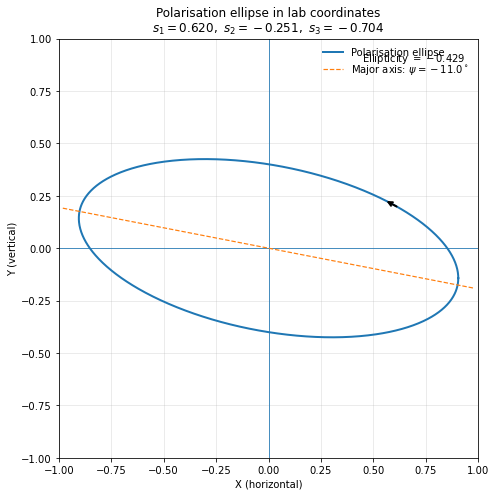

In [12]:
rotated_pump_beam_20 = analyse_polarisation(
    5,
    1.18,
    2.4,
    4,
    0.79,
    4.5,
    0.01
)
 #Input order:
        #Ix_raw       : intensity measured with polariser along x
        #Iy_raw       : intensity measured with polariser along y
        #I45_raw      : intensity measured at +45 degrees
        #Im45_raw     : intensity measured at -45 degrees
        #Iplus_raw    : QWP = +45 degrees, polariser = x
        #Iminus_raw   : QWP = -45 degrees, polariser = x
        #background


========== Background-corrected intensities ==========
Ix     = 7.9900
Iy     = 1.9700
I45    = 4.6200
I-45   = 5.8200
Iplus  = 1.0900
Iminus = 6.9900

========== Total intensities ==========
Ix + Iy          = 9.9600
I45 + I-45       = 10.4400
Iplus + Iminus   = 8.0800
Mean S0          = 9.4933

========== Stokes parameters ==========
S0 = 9.4933
S1 = 6.0200
S2 = -1.2000
S3 = -5.9000

========== Normalised Stokes parameters ==========
s1 = 0.6044
s2 = -0.1149
s3 = -0.7302

========== Degrees of polarisation ==========
DOLP = 0.6152
DOCP = -0.7302
DOP  = 0.9548

========== Polarisation ellipse ==========
Major-axis angle psi = -5.38 degrees
Ellipticity angle chi = -24.94 degrees
Ellipticity (signed minor/major axis ratio) = -0.4651
Minor/major axis ratio = 0.4651

========== Jones vector in the x/y basis ==========
[ 0.90360483+0.j         -0.06661025-0.42315646j]

Equivalent form with Ex real:
|Ey| / |Ex| = 0.4741
Relative phase delta = -98.95 degrees


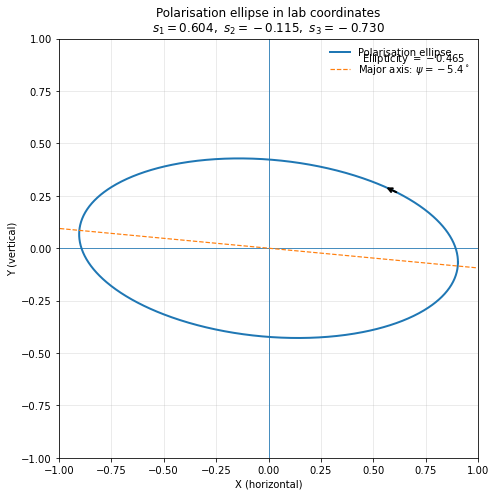

In [14]:
rotated_pump_beam_30 = analyse_polarisation(
    8,
    1.98,
    4.63,
    5.83,
    1.1,
    7,
    0.01
)
 #Input order:
        #Ix_raw       : intensity measured with polariser along x
        #Iy_raw       : intensity measured with polariser along y
        #I45_raw      : intensity measured at +45 degrees
        #Im45_raw     : intensity measured at -45 degrees
        #Iplus_raw    : QWP = +45 degrees, polariser = x
        #Iminus_raw   : QWP = -45 degrees, polariser = x
        #background


========== Background-corrected intensities ==========
Ix     = 9.8000
Iy     = 1.9200
I45    = 4.9200
I-45   = 8.4900
Iplus  = 1.4300
Iminus = 9.5600

========== Total intensities ==========
Ix + Iy          = 11.7200
I45 + I-45       = 13.4100
Iplus + Iminus   = 10.9900
Mean S0          = 12.0400

========== Stokes parameters ==========
S0 = 12.0400
S1 = 7.8800
S2 = -3.5700
S3 = -8.1300

========== Normalised Stokes parameters ==========
s1 = 0.6724
s2 = -0.2662
s3 = -0.7398

========== Degrees of polarisation ==========
DOLP = 0.7231
DOCP = -0.7398
DOP  = 1.0345

This normally indicates measurement uncertainty, power drift, angle error or imperfect calibration.
The Jones vector and ellipse use the Stokes vector projected onto the unit Poincare sphere.

========== Polarisation ellipse ==========
Major-axis angle psi = -10.80 degrees
Ellipticity angle chi = -22.83 degrees
Ellipticity (signed minor/major axis ratio) = -0.4209
Minor/major axis ratio = 0.4209

========== Jones vector in

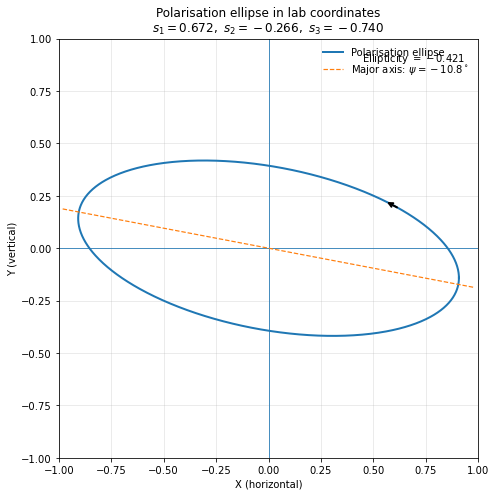

In [15]:
rotated_pump_beam_40 = analyse_polarisation(
    9.81,
    1.93,
    4.93,
    8.5,
    1.44,
    9.57,
    0.01
)
 #Input order:
        #Ix_raw       : intensity measured with polariser along x
        #Iy_raw       : intensity measured with polariser along y
        #I45_raw      : intensity measured at +45 degrees
        #Im45_raw     : intensity measured at -45 degrees
        #Iplus_raw    : QWP = +45 degrees, polariser = x
        #Iminus_raw   : QWP = -45 degrees, polariser = x
        #background


========== Background-corrected intensities ==========
Ix     = 0.5900
Iy     = 0.3990
I45    = 0.4100
I-45   = 0.5000
Iplus  = 0.2450
Iminus = 0.1750

========== Total intensities ==========
Ix + Iy          = 0.9890
I45 + I-45       = 0.9100
Iplus + Iminus   = 0.4200
Mean S0          = 0.7730

========== Stokes parameters ==========
S0 = 0.7730
S1 = 0.1910
S2 = -0.0900
S3 = 0.0700

========== Normalised Stokes parameters ==========
s1 = 0.1931
s2 = -0.0989
s3 = 0.1667

========== Degrees of polarisation ==========
DOLP = 0.2170
DOCP = 0.1667
DOP  = 0.2736

========== Polarisation ellipse ==========
Major-axis angle psi = -13.56 degrees
Ellipticity angle chi = 18.76 degrees
Ellipticity (signed minor/major axis ratio) = 0.3397
Minor/major axis ratio = 0.3397

========== Jones vector in the x/y basis ==========
[ 0.92354409+0.j         -0.19570392+0.32979734j]

Equivalent form with Ex real:
|Ey| / |Ex| = 0.4152
Relative phase delta = 120.69 degrees


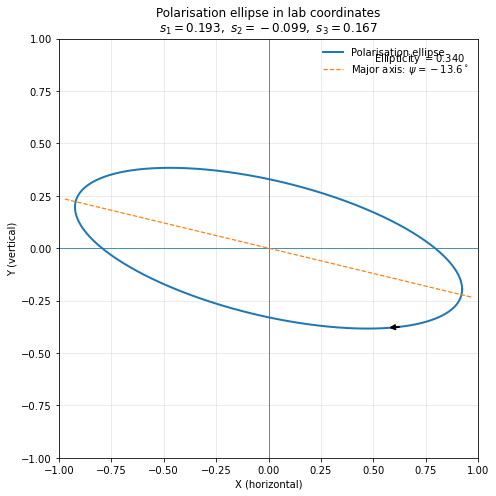

In [3]:
back_side = analyse_polarisation(
    0.6,
    0.409,
    0.42,
    0.51,
    0.255,
    0.185,
    0.01
)
 #Input order:
        #Ix_raw       : intensity measured with polariser along x
        #Iy_raw       : intensity measured with polariser along y
        #I45_raw      : intensity measured at +45 degrees
        #Im45_raw     : intensity measured at -45 degrees
        #Iplus_raw    : QWP = +45 degrees, polariser = x
        #Iminus_raw   : QWP = -45 degrees, polariser = x
        #background


========== Background-corrected intensities ==========
Ix     = 0.2000
Iy     = 0.0650
I45    = 0.0780
I-45   = 0.1630
Iplus  = 0.0900
Iminus = 0.1100

========== Total intensities ==========
Ix + Iy          = 0.2650
I45 + I-45       = 0.2410
Iplus + Iminus   = 0.2000
Mean S0          = 0.2353

========== Stokes parameters ==========
S0 = 0.2353
S1 = 0.1350
S2 = -0.0850
S3 = -0.0200

========== Normalised Stokes parameters ==========
s1 = 0.5094
s2 = -0.3527
s3 = -0.1000

========== Degrees of polarisation ==========
DOLP = 0.6196
DOCP = -0.1000
DOP  = 0.6276

========== Polarisation ellipse ==========
Major-axis angle psi = -17.35 degrees
Ellipticity angle chi = -4.58 degrees
Ellipticity (signed minor/major axis ratio) = -0.0802
Minor/major axis ratio = 0.0802

========== Jones vector in the x/y basis ==========
[ 0.95175628+0.j         -0.29521819-0.08370304j]

Equivalent form with Ex real:
|Ey| / |Ex| = 0.3224
Relative phase delta = -164.17 degrees


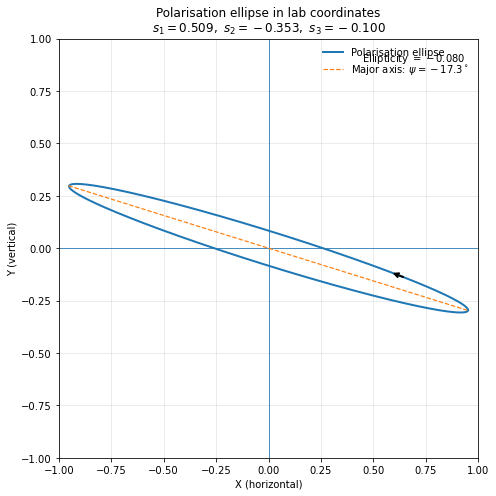

In [4]:
back_side2 = analyse_polarisation(
    0.21,
    0.075,
    0.088,
    0.173,
    0.1,
    0.12,
    0.01
)